# Task 3 Deep Learning with Explainability

I would train a neural network to estimate traffic volume using time and weather features. I would retain the chronological training, validation and test split from Task 1. Preprocessing will be fitted using training data only.

For explainability, I woiyuld use SHAP with the Task 1 Random Forest regression model, which predicts te same target using the same features. Its explanations describe the Random Forest model rather than the neural network.

In [2]:
# Import packages and configureLogging

import logging
from pathlib import Path
from importlib.util import find_spec

import numpy as np
import pandas as pd
import sklearn

PART3_DIR = Path.cwd().parent
REPO_DIR = PART3_DIR.parent

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
    handlers=[
        logging.StreamHandler(),
        logging.FileHandler(
            PART3_DIR / "part3_deep_learning.log",
            encoding="utf-8"
        )
    ],
    force=True
)

logger = logging.getLogger(__name__)

logger.info("Deep learning and explainability notebook has started.")



# Check availability before choosing the neural network framework.
package_status = pd.DataFrame([
    {
        "package": package,
        "available": find_spec(package) is not None
    }
    for package in ["tensorflow", "torch", "shap"]
])

display(package_status)


logger.info(
    "Package versions: NumPy %s, Pandas %s, scikit-learn %s.",
    np.__version__,
    pd.__version__,
    sklearn.__version__
)

2026-10-10 23:33:15,894 | INFO | __main__ | Deep learning and explainability notebook has started.


,package,available
0,tensorflow,True
1,torch,True
2,shap,True


2026-10-10 23:33:15,908 | INFO | __main__ | Package versions: NumPy 2.4.6, Pandas 2.3.3, scikit-learn 1.7.2.


## Prepare the deep learning and explainability packages

I would use TensorFlow to build the neural network and SHAP to explain the comparable Random Forest regression model. I would check that the packages import successfully and record their versions.

In [2]:
%pip install shap

   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 755.4/755.4 kB 7.4 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Verify imports and record package versions.
import tensorflow as tf
import shap

logger.info(
    "TensorFlow %s and SHAP %s imported successfully.",
    tf.__version__,
    shap.__version__
)

2026-10-10 23:33:22,370 | INFO | __main__ | TensorFlow 2.21.0 and SHAP 0.53.0 imported successfully.


## Load the data and recreate the chronological split

I would reuse the raw dataset and cleaning functions from Task 1.Invalid temperature and rainfall readings are marked as missing. They will be filled using the saved training-only imputation settings in the next step.

I woudl split the unique timestamps into 75% training, 15% validation and 10% testing. Records with the same timestamp remain together like in Part2.

In [4]:
# Load the raw data 

import sys
import joblib

part2_path = REPO_DIR / "capstone_part2"

if str(part2_path) not in sys.path:
    sys.path.insert(0, str(part2_path))

from pipeline import (
    validate_schema,
    standardise_categories,
    clean_datetime,
    convert_numeric_columns,
    fill_missing_categories,
    clean_other_numbers,
    remove_duplicates
)


input_path = (
    REPO_DIR
    / "part1_data_analytics"
    / "data"
    / "Metro_Interstate_Traffic_Volume.csv"
)

# Locate the original dataset if its folder differs.
if not input_path.exists():
    matches = list(
        (REPO_DIR / "part1_data_analytics").rglob(
            "Metro_Interstate_Traffic_Volume.csv"
        )
    )
    if len(matches) != 1:
        raise FileNotFoundError(
            "Could not uniquely locate the raw traffic dataset."
        )
    input_path = matches[0]

data = pd.read_csv(input_path, keep_default_na=False)
validate_schema(data)

model_data = data.copy()

for cleaning_function in [
    standardise_categories,
    clean_datetime,
    convert_numeric_columns,
    fill_missing_categories,
    clean_other_numbers,
    remove_duplicates
]:
    model_data = cleaning_function(model_data)


# Mark invalid readings before applying training-only imputation.
invalid_temperature = (
    ~np.isfinite(model_data["temp"])
    | (model_data["temp"] <= 0)
)

invalid_rainfall = (
    ~np.isfinite(model_data["rain_1h"])
    | (model_data["rain_1h"] < 0)
    | (model_data["rain_1h"] > 9000)
)



for column, invalid in [
    ("temp", invalid_temperature),
    ("rain_1h", invalid_rainfall)
]:
    model_data.loc[invalid, column] = np.nan

    if invalid.any():
        logger.warning(
            "Marked %s invalid %s readings as missing.",
            int(invalid.sum()),
            column
        )

model_data = (
    model_data.sort_values("date_time", kind="stable")
    .reset_index(drop=True)
)

#Keep all records with the same timestamp in one set.
timestamps = (
    model_data["date_time"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

validation_start = timestamps.iloc[int(len(timestamps) * 0.75)]
test_start = timestamps.iloc[int(len(timestamps) * 0.90)]

train_data = model_data.loc[
    model_data["date_time"] < validation_start
].copy()

validation_data = model_data.loc[
    (model_data["date_time"] >= validation_start)
    & (model_data["date_time"] < test_start)
].copy()

test_data = model_data.loc[
    model_data["date_time"] >= test_start
].copy()

assert train_data["date_time"].max() < validation_data["date_time"].min()
assert validation_data["date_time"].max() < test_data["date_time"].min()
assert (
    len(train_data) + len(validation_data) + len(test_data)
    == len(model_data)
)


assert (
    len(train_data), len(validation_data), len(test_data)
) == (35873, 7370, 4944)

logger.info(
    "Chronological split has  completed. Training: %s, validation: %s, test: %s rows.",
    len(train_data),
    len(validation_data),
    len(test_data)
)



display(pd.DataFrame([
    {
        "set": name,
        "rows": len(frame),
        "first_date": frame["date_time"].min(),
        "last_date": frame["date_time"].max()
    }
    for name, frame in [
        ("Training", train_data),
        ("Validation", validation_data),
        ("Test", test_data)
    ]
]))



2026-10-10 23:35:36,451 | INFO | pipeline | Column check has passed. All required columns are present.
2026-10-10 23:35:36,494 | INFO | pipeline | holiday: no text changes are required.
2026-10-10 23:35:36,523 | INFO | pipeline | weather_main: no text changes are required.
2026-10-10 23:35:36,552 | WARNING | pipeline | weather_description: changed 1730 rows to fix spaces and capital letters.
2026-10-10 23:35:36,594 | INFO | pipeline | Date check has passed. No missing or invalid dates.
2026-10-10 23:35:36,594 | INFO | pipeline | date_time is now in datetime format.
2026-10-10 23:35:36,608 | INFO | pipeline | temp: number conversion finished.
2026-10-10 23:35:36,611 | INFO | pipeline | rain_1h: number conversion finished.
2026-10-10 23:35:36,614 | INFO | pipeline | snow_1h: number conversion finished.
2026-10-10 23:35:36,617 | INFO | pipeline | clouds_all: number conversion finished.
2026-10-10 23:35:36,620 | INFO | pipeline | traffic_volume: number conversion finished.
2026-10-10 23:35

,set,rows,first_date,last_date
0,Training,35873,2012-10-02 09:00:00,2017-08-02 23:00:00
1,Validation,7370,2017-08-03 00:00:00,2018-04-14 15:00:00
2,Test,4944,2018-04-14 16:00:00,2018-09-30 23:00:00


## Reuse training preparation and create model features

I would fill missing temperature and rainfall readings using the training-only medians saved in Task 1.

I woudl recreate the same time, holiday and weather features. The saved Random Forest preprocessing transforms these features consistently for comparison with the neural network.

Traffic volume is the regression target and is excluded from the model inputs.

In [5]:
# Load the preparation settings and comparable regression model.


preparation_config = joblib.load(
    PART3_DIR / "models" / "preparation_config_v1.joblib"
)

reference_model = joblib.load(
    PART3_DIR / "models" / "random_forest_regression_v1.joblib"
)

imputation_values = preparation_config["imputation_values"]
feature_columns = preparation_config["feature_columns"]




def prepare_model_features(frame):
    prepared = frame.copy()

    # Apply medians calculated from Task 1 training data only.
    for column in ["temp", "rain_1h"]:
        missing = prepared[column].isna()

        replacements = (
            prepared["date_time"].dt.month
            .map(imputation_values[column]["monthly"])
            .fillna(imputation_values[column]["fallback"])
        )

        prepared.loc[missing, column] = replacements.loc[missing]

    # Recreate the Task 1 time and holiday features.
    prepared["hour"] = prepared["date_time"].dt.hour
    prepared["day_of_week"] = prepared["date_time"].dt.dayofweek
    prepared["month"] = prepared["date_time"].dt.month

    prepared["is_weekend"] = (
        prepared["day_of_week"] >= 5
    ).astype(int)

    prepared["is_holiday"] = (
        ~prepared["holiday"].isin(["None", "Unknown"])
    ).astype(int)

    hour_angle = 2 * np.pi * prepared["hour"] / 24
    weekday_angle = 2 * np.pi * prepared["day_of_week"] / 7

    prepared["hour_sin"] = np.sin(hour_angle)
    prepared["hour_cos"] = np.cos(hour_angle)
    prepared["weekday_sin"] = np.sin(weekday_angle)
    prepared["weekday_cos"] = np.cos(weekday_angle)

    # Recreate the Task 1 weather indicators.
    prepared["has_rain"] = (
        prepared["rain_1h"] > 0
    ).astype(int)

    prepared["has_snow"] = (
        prepared["snow_1h"] > 0
    ).astype(int)

    prepared["is_low_visibility"] = (
        prepared["weather_main"].isin(
            preparation_config["low_visibility_weather"]
        )
    ).astype(int)

    assert not prepared[feature_columns].isna().any().any()

    return prepared


train_data = prepare_model_features(train_data)
validation_data = prepare_model_features(validation_data)
test_data = prepare_model_features(test_data)

X_train = train_data[feature_columns].copy()
X_validation = validation_data[feature_columns].copy()
X_test = test_data[feature_columns].copy()

y_train = train_data["traffic_volume"].to_numpy(dtype=np.float32)
y_validation = validation_data["traffic_volume"].to_numpy(
    dtype=np.float32
)
y_test = test_data["traffic_volume"].to_numpy(dtype=np.float32)

#Reuse the prerocessor already fitted on Task 1 training data.

preprocessor = reference_model.named_steps["preprocessor"]

X_train_nn = np.asarray(
    preprocessor.transform(X_train),
    dtype=np.float32
)
X_validation_nn = np.asarray(
    preprocessor.transform(X_validation),
    dtype=np.float32
)
X_test_nn = np.asarray(
    preprocessor.transform(X_test),
    dtype=np.float32
)

for inputs in [X_train_nn, X_validation_nn, X_test_nn]:
    assert np.isfinite(inputs).all()

logger.info(
    "Prepared neural network inputs with %s transformed features.",
    X_train_nn.shape[1]
)


display(pd.DataFrame({
    "set": ["Training", "Validation", "Test"],
    "rows": [
        len(X_train_nn),
        len(X_validation_nn),
        len(X_test_nn)
    ],
    "transformed_features": [
        X_train_nn.shape[1],
        X_validation_nn.shape[1],
        X_test_nn.shape[1]
    ]
}))


2026-10-10 23:38:18,528 | INFO | __main__ | Prepared neural network inputs with 27 transformed features.


,set,rows,transformed_features
0,Training,35873,27
1,Validation,7370,27
2,Test,4944,27


In [6]:
# Build and train the traffic-volume neural network.
tf.keras.utils.set_random_seed(42)

# Calculat target scaling from training data only.
target_mean = float(y_train.mean())
target_std = float(y_train.std())


assert target_std > 0

y_train_scaled = (y_train - target_mean) / target_std
y_validation_scaled = (
    y_validation - target_mean
) / target_std

neural_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_nn.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

neural_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)




# Record progress through the notebook logger.
class TrainingLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        if epoch == 0 or (epoch + 1) % 10 == 0:
            logger.info(
                "Epoch %s completed. Training loss %.4f, validation loss %.4f.",
                epoch + 1,
                logs["loss"],
                logs["val_loss"]
            )


logger.info("Started training the traffic-volume neural network.")

history = neural_model.fit(
    X_train_nn,
    y_train_scaled,
    validation_data=(
        X_validation_nn,
        y_validation_scaled
    ),
    epochs=100,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping, TrainingLogger()],
    verbose=0
)

training_history = pd.DataFrame(history.history)
training_history.insert(
    0,
    "epoch",
    np.arange(1, len(training_history) + 1)
)

best_epoch = int(
    training_history.loc[
        training_history["val_loss"].idxmin(),
        "epoch"
    ]
)


logger.info(
    "Training completed after %s epochs. Best validation loss occurred at epoch %s.",
    len(training_history),
    best_epoch
)

display(training_history.tail(10).round(4))

2026-10-10 23:40:37,440 | WARNING | tensorflow | TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.
2026-10-10 23:40:37,448 | INFO | __main__ | Started training the traffic-volume neural network.
2026-10-10 23:40:40,123 | INFO | __main__ | Epoch 1 completed. Training loss 0.3518, validation loss 0.1813.
2026-10-10 23:40:44,790 | INFO | __main__ | Epoch 10 completed. Training loss 0.0623, validation loss 0.0719.
2026-10-10 23:40:48,549 | INFO | __main__ | Epoch 20 completed. Training loss 0.0585, validation loss 0.0699.
2026-10-10 23:40:53,951 | INFO | __main__ | Epoch 30 completed. Training loss 0.0570, validation loss 0.0692.
2026-10-10 23:40:57,465 | INFO | __main__ | Training completed after 37 epochs. Best validation loss occurred at epoch 27.


,epoch,loss,val_loss
27,28,0.0572,0.0691
28,29,0.0572,0.0691
29,30,0.0570,0.0692
30,31,0.0569,0.0694
31,32,0.0568,0.0693
32,33,0.0567,0.0693
33,34,0.0565,0.0693
34,35,0.0566,0.0692
35,36,0.0564,0.0694
36,37,0.0565,0.0692


## Review training and validation performance

I would plot training and validation loss to inspect the learning process.

I woudl convert neural network predictions back to traffic-volume units and calculate validation MAE and R squared. I would compare these results with the Task 1 Random Forest using the same validation records.

The losses in the training chart use the standardised target. MAE is reported in original traffic-volume units.

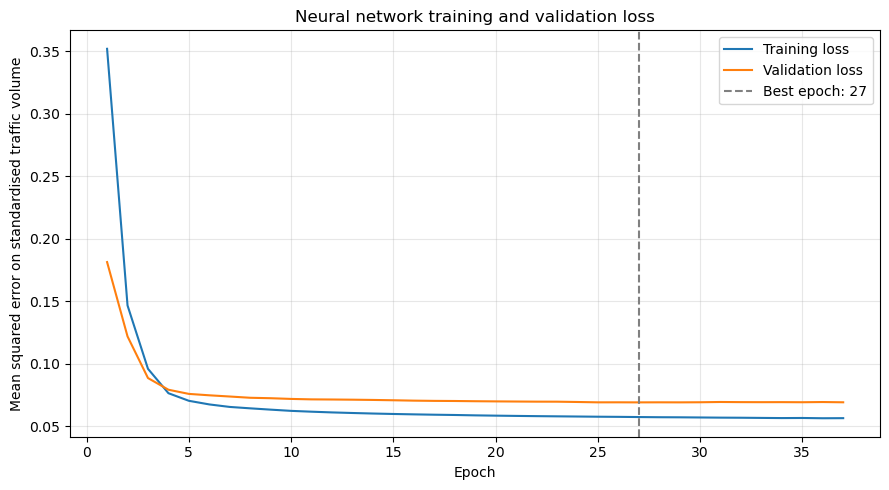

2026-10-10 23:43:12,380 | INFO | __main__ | Neural network validation MAE 316.44 and R squared 0.9307.


,model,validation_MAE,validation_R_squared
0,Neural Network,316.4414,0.9307
1,Random Forest,317.5692,0.9256


In [7]:
# Plot the training history.

import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

training_fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    training_history["epoch"],
    training_history["loss"],
    label="Training loss"
)
ax.plot(
    training_history["epoch"],
    training_history["val_loss"],
    label="Validation loss"
)



ax.axvline(
    best_epoch,
    color="grey",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

ax.set_title("Neural network training and validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error on standardised traffic volume")
ax.legend()
ax.grid(alpha=0.3)



training_fig.tight_layout()
plt.show()

#Convert neural network predictions to original traffic-volume units.
nn_validation_predictions = (
    neural_model.predict(X_validation_nn, verbose=0).ravel()
    * target_std
    + target_mean
)

rf_validation_predictions = reference_model.predict(X_validation)

assert np.isfinite(nn_validation_predictions).all()

validation_comparison = pd.DataFrame([
    {
        "model": name,
        "validation_MAE": mean_absolute_error(
            y_validation, predictions
        ),
        "validation_R_squared": r2_score(
            y_validation, predictions
        )
    }
    for name, predictions in [
        ("Neural Network", nn_validation_predictions),
        ("Random Forest", rf_validation_predictions)
    ]
])


logger.info(
    "Neural network validation MAE %.2f and R squared %.4f.",
    validation_comparison.iloc[0]["validation_MAE"],
    validation_comparison.iloc[0]["validation_R_squared"]
)

display(validation_comparison.round(4))



## Evaluate the models on the held out test set

The neural network and Random Forest had similar validation MAE.

I would now evaluate both models on the same chronological test records, without changing their settings. I rwould eport MAE in traffic-volume units and R squared.


In [8]:
#Evaluate the fixed models on the held-out test set.

nn_test_predictions = (
    neural_model.predict(X_test_nn, verbose=0).ravel()
    * target_std
    + target_mean
)

rf_test_predictions = reference_model.predict(X_test)

assert np.isfinite(nn_test_predictions).all()
assert np.isfinite(rf_test_predictions).all()

test_comparison = pd.DataFrame([
    {
        "model": name,
        "test_MAE": mean_absolute_error(
            y_test, predictions
        ),
        "test_R_squared": r2_score(
            y_test, predictions
        )
    }
    for name, predictions in [
        ("Neural Network", nn_test_predictions),
        ("Random Forest", rf_test_predictions)
    ]
])


# Retain predictions for later reporting and saving.
test_prediction_results = pd.DataFrame({
    "date_time": test_data["date_time"].to_numpy(),
    "actual_traffic_volume": y_test,
    "neural_network_prediction": nn_test_predictions,
    "random_forest_prediction": rf_test_predictions
})

logger.info(
    "Completed held-out test evaluation for both regression models."
)


display(test_comparison.round(4))

2026-10-10 23:46:06,250 | INFO | __main__ | Completed held-out test evaluation for both regression models.


,model,test_MAE,test_R_squared
0,Neural Network,256.9366,0.9455
1,Random Forest,250.8358,0.9448


## Explain the comparable Random Forest model

I would calculate SHAP values for a reproducible sample of 200 test records.

SHAP values describe how each transformed feature contributes to the Random Forest prediction relative to its baseline. Mean absolute SHAP values summarise contribution size across the sample.

These explanations apply to the Random Forest rather than the neural network. Related features, such as hour and its cyclical encodings, can share contributions. 

2026-10-10 23:47:58,482 | INFO | __main__ | Started SHAP explanations for 200 test records.
2026-10-10 23:49:34,358 | INFO | __main__ | SHAP explanations ae completed and prediction reconstruction passed.


,feature,mean_absolute_SHAP
0,numeric__hour_cos,1438.3837
1,numeric__hour,447.4004
2,numeric__hour_sin,204.0781
3,numeric__day_of_week,180.9715
4,numeric__weekday_sin,132.7563
5,numeric__is_weekend,117.0251
6,numeric__temp,62.1642
7,numeric__weekday_cos,54.7787
8,numeric__month,44.7153
9,numeric__clouds_all,24.9140


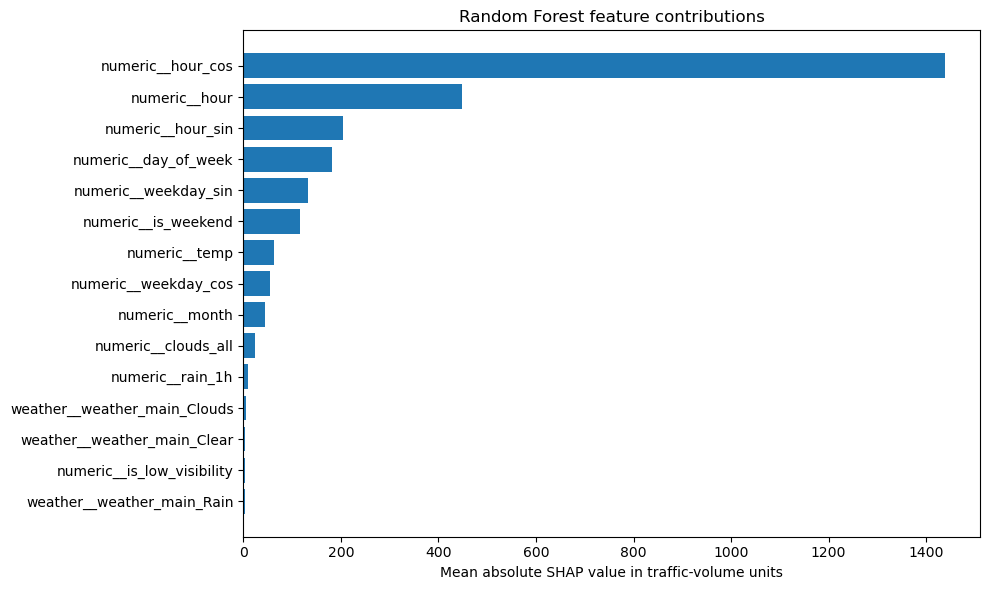

In [9]:
# Select a reproducible sample for Random Forest explanations.

explanation_inputs = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)


# Retain the original preprocessing precision for SHAP.
explanation_transformed = preprocessor.transform(
    explanation_inputs
)

transformed_feature_names = (
    preprocessor.get_feature_names_out()
)

forest_regressor = reference_model.named_steps["model"]

logger.info(
    "Started SHAP explanations for %s test records.",
    len(explanation_inputs)
)

# Use training sample counts stored in the fitted trees.
shap_explainer = shap.TreeExplainer(
    forest_regressor,
    feature_perturbation="tree_path_dependent",
    model_output="raw",
    feature_names=list(transformed_feature_names)
)

shap_values = shap_explainer(
    explanation_transformed,
    check_additivity=True
)

# Verify that contributions reconstruct model predictions.
explanation_predictions = reference_model.predict(
    explanation_inputs
)

reconstructed_predictions = (
    np.asarray(shap_values.base_values).reshape(-1)
    + shap_values.values.sum(axis=1)
)

np.testing.assert_allclose(
    reconstructed_predictions,
    explanation_predictions,
    rtol=1e-5,
    atol=1e-3
)

shap_importance = pd.DataFrame({
    "feature": transformed_feature_names,
    "mean_absolute_SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
}).sort_values(
    "mean_absolute_SHAP",
    ascending=False
).reset_index(drop=True)


logger.info(
    "SHAP explanations ae completed and prediction reconstruction passed."
)

display(shap_importance.head(15).round(4))

# Plot the largest average feature contributions.
shap_global_fig, ax = plt.subplots(figsize=(10, 6))

plot_importance = shap_importance.head(15).iloc[::-1]

ax.barh(
    plot_importance["feature"],
    plot_importance["mean_absolute_SHAP"]
)

ax.set_title("Random Forest feature contributions")
ax.set_xlabel("Mean absolute SHAP value in traffic-volume units")


shap_global_fig.tight_layout()
plt.show()

## Interpret the explanations

Time-of-day features had the largest mean absolute SHAP values in the 200-record sample. Weekday and weekend features also contributed more than individual weather features.

These values describe contribution size, not whether    feature always increases or decreases traffic volume. Related time features share information, so their individual rankings should be interpreted together.

I also examine one sampled prediction. Positive SHAP values increasere the Random Forest estimate relative to its baseline, while negative values decrease it. This explanation describes the Random Forest, not the neural network.

,date_time,actual_traffic_volume,random_forest_prediction,SHAP_baseline,sum_of_contributions
0,2018-04-18 15:00:00,5835,5801.5944,3244.9937,2556.6007


,feature,SHAP_contribution,absolute_contribution
0,numeric__hour_cos,1369.8387,1369.8387
1,numeric__hour,427.0427,427.0427
2,numeric__hour_sin,245.8736,245.8736
3,numeric__day_of_week,146.9610,146.9610
4,numeric__month,105.2458,105.2458
5,numeric__weekday_sin,88.5191,88.5191
6,numeric__is_weekend,85.5092,85.5092
7,numeric__temp,50.1137,50.1137
8,numeric__weekday_cos,30.6217,30.6217
9,numeric__clouds_all,-22.2448,22.2448


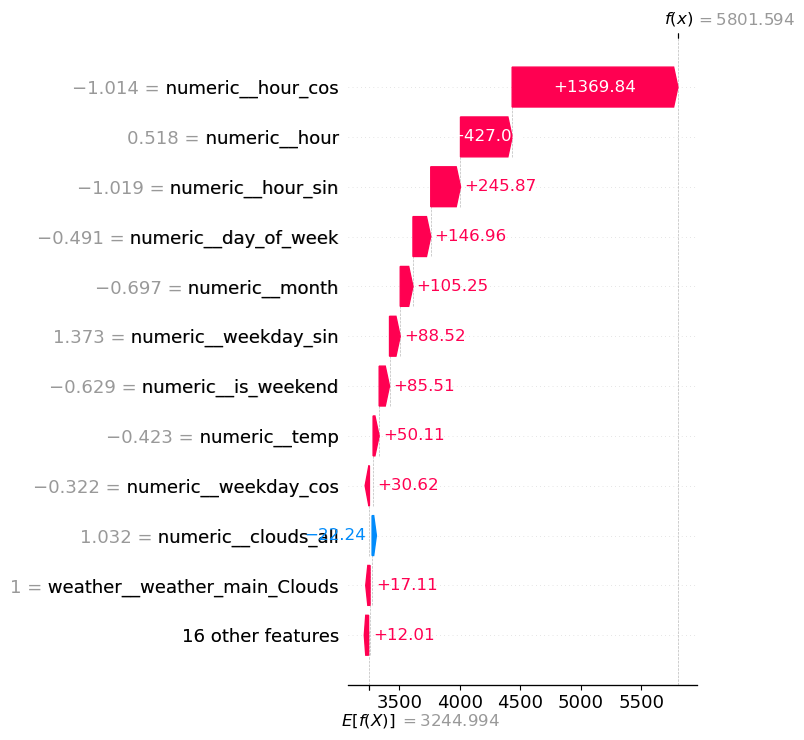

2026-10-10 23:52:41,982 | INFO | __main__ | Prepared a local Random Forest explanation for one sampled test record.


In [10]:


# Explain one record from the existing SHAP sample.


example_position = 0
example_index = explanation_inputs.index[example_position]

local_contributions = pd.DataFrame({
    "feature": transformed_feature_names,
    "SHAP_contribution": shap_values.values[example_position]
})

local_contributions["absolute_contribution"] = (
    local_contributions["SHAP_contribution"].abs()
)

local_contributions = local_contributions.sort_values(
    "absolute_contribution",
    ascending=False
).reset_index(drop=True)



example_summary = pd.DataFrame([{
    "date_time": test_data.loc[example_index, "date_time"],
    "actual_traffic_volume": test_data.loc[
        example_index, "traffic_volume"
    ],
    "random_forest_prediction": explanation_predictions[
        example_position
    ],
    "SHAP_baseline": float(
        np.asarray(shap_values.base_values).reshape(-1)[
            example_position
        ]
    ),
    "sum_of_contributions": float(
        shap_values.values[example_position].sum()
    )
}])


display(example_summary.round(4))
display(local_contributions.head(10).round(4))


# Display the complete additive explanation for this record.
shap.plots.waterfall(
    shap_values[example_position],
    max_display=12,
    show=False
)

shap_local_fig = plt.gcf()
shap_local_fig.tight_layout()
plt.show()

logger.info(
    "Prepared a local Random Forest explanation for one sampled test record."
)


## Save the model and execution results

I would save the neural network, fitted preprocessing and target scaling settings so predictions can be reproduced.

I would also save the training history, validation and test comparisons, test predictions, SHAP contributions and explanation charts.

After saving, I rewoudl load the neural network and preprocessing settings and check that they reproduce the original predictions.

In [11]:
# Save Task 3 models, results and charts.


models_dir = PART3_DIR / "models"
results_dir = PART3_DIR / "results"
figures_dir = PART3_DIR / "figures"

for directory in [models_dir, results_dir, figures_dir]:
    directory.mkdir(parents=True, exist_ok=True)

neural_model.save(
    models_dir / "neural_network_traffic_v1.keras"
)

joblib.dump(
    preprocessor,
    models_dir / "neural_network_preprocessor_v1.joblib",
    compress=3
)


neural_config = {
    "feature_columns": feature_columns,
    "target_mean": target_mean,
    "target_std": target_std,
    "imputation_values": imputation_values,
    "low_visibility_weather": preparation_config[
        "low_visibility_weather"
    ],
    "hidden_layers": [64, 32],
    "learning_rate": 0.001,
    "batch_size": 256,
    "maximum_epochs": 100,
    "early_stopping_patience": 10,
    "epochs_completed": len(training_history),
    "best_epoch": best_epoch,
    "random_state": 42,
    "tensorflow_version": tf.__version__,
    "shap_version": shap.__version__
}

joblib.dump(
    neural_config,
    models_dir / "neural_network_config_v1.joblib",
    compress=3
)


logger.info("Saved the neural network and preparation settings.")

result_tables = {
    "neural_network_training_history": training_history,
    "task3_validation_comparison": validation_comparison,
    "task3_test_comparison": test_comparison,
    "task3_test_predictions": test_prediction_results,
    "shap_global_importance": shap_importance,
    "shap_local_contributions": local_contributions,
    "shap_example_summary": example_summary
}

for filename, table in result_tables.items():
    table.to_csv(
        results_dir / f"{filename}.csv",
        index=False
    )
    logger.info("Saved results/%s.csv.", filename)

# Preserve SHAP values and the corresponding sampled records.
shap_sample_results = pd.DataFrame(
    shap_values.values,
    columns=transformed_feature_names
)
shap_sample_results.insert(
    0,
    "date_time",
    test_data.loc[
        explanation_inputs.index, "date_time"
    ].to_numpy()
)
shap_sample_results.insert(
    1,
    "baseline",
    np.asarray(shap_values.base_values).reshape(-1)
)
shap_sample_results.insert(
    2,
    "prediction",
    explanation_predictions
)
shap_sample_results.to_csv(
    results_dir / "shap_sample_contributions.csv",
    index=False
)


for filename, figure in [
    ("neural_network_training_curve", training_fig),
    ("shap_global_importance", shap_global_fig),
    ("shap_local_waterfall", shap_local_fig)
]:
    figure.savefig(
        figures_dir / f"{filename}.png",
        dpi=150,
        bbox_inches="tight"
    )
    logger.info("Saved figures/%s.png.", filename)

# Verify predictions after reloading the saved artifacts.
loaded_neural_model = tf.keras.models.load_model(
    models_dir / "neural_network_traffic_v1.keras"
)
loaded_preprocessor = joblib.load(
    models_dir / "neural_network_preprocessor_v1.joblib"
)
loaded_config = joblib.load(
    models_dir / "neural_network_config_v1.joblib"
)



reload_inputs = np.asarray(
    loaded_preprocessor.transform(X_validation.head(20)),
    dtype=np.float32
)

reloaded_predictions = (
    loaded_neural_model.predict(
        reload_inputs, verbose=0
    ).ravel()
    * loaded_config["target_std"]
    + loaded_config["target_mean"]
)



np.testing.assert_allclose(
    nn_validation_predictions[:20],
    reloaded_predictions,
    rtol=1e-5,
    atol=0.01
)

logger.info(
    "The saved neural network and preprocessing passed the reload check."
)

2026-10-10 23:55:41,172 | INFO | __main__ | Saved the neural network and preparation settings.
2026-10-10 23:55:41,186 | INFO | __main__ | Saved results/neural_network_training_history.csv.
2026-10-10 23:55:41,190 | INFO | __main__ | Saved results/task3_validation_comparison.csv.
2026-10-10 23:55:41,193 | INFO | __main__ | Saved results/task3_test_comparison.csv.
2026-10-10 23:55:41,232 | INFO | __main__ | Saved results/task3_test_predictions.csv.
2026-10-10 23:55:41,238 | INFO | __main__ | Saved results/shap_global_importance.csv.
2026-10-10 23:55:41,243 | INFO | __main__ | Saved results/shap_local_contributions.csv.
2026-10-10 23:55:41,249 | INFO | __main__ | Saved results/shap_example_summary.csv.
2026-10-10 23:55:41,467 | INFO | __main__ | Saved figures/neural_network_training_curve.png.
2026-10-10 23:55:41,695 | INFO | __main__ | Saved figures/shap_global_importance.png.
2026-10-10 23:55:42,072 | INFO | __main__ | Saved figures/shap_local_waterfall.png.
2026-10-10 23:55:42,325 | I